# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170315         
NAME = "Rohit Poddar"           

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170315   Name: Rohit Poddar   Fingerprint: 39F8A566   Tickets: 12

Ticket_ID                                                                 Ticket_Text
      T01                The Python is running slowly. The same problem occurs again.
      T02                                              Error code 0x80070005 appears.
      T03        I reinstalled the email when connected to campus Wi-Fi. Please help.
      T04       I tried restarting the printer while uploading the file. Please help.
      T05 I couldn't connect to the LMS while uploading the file. Can you check this?
      T06                               The printer has stopped syncing. Please help.
      T07                 Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T08                                       The Wi-Fi works, but the VPN doesn't.
      T09                                          Dr. Rao's lab PC (No. 14) is down.
      T10               LMS is not working when I use mo

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:


rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation Tokens": q1_table["Punctuation Tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": q1_table["Unique Tokens"].sum(),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

print(q1_table)

selected_ticket = FOCUS[0]

ticket_text = df.loc[
    df["Ticket_ID"] == selected_ticket,
    "Ticket_Text"
].iloc[0]

result = process_ticket(ticket_text)

print("Selected Ticket:", selected_ticket)
print("Ticket Text:", ticket_text)

print("\nSentences:")
print(result["sentences"])

print("\nTokens:")
print(result["tokens"])

print("\nPunctuation Tokens:")
print(result["punct"])

print("\nStopwords:")
print(result["stops"])

print("\nFinal Tokens:")
print(result["final"])

   Ticket_ID  Sentences  Tokens  Punctuation Tokens  Stopwords  Unique Tokens  \
0        T01          2      12                   2          5             10   
1        T02          1       5                   1          0              5   
2        T03          2      13                   2          4             12   
3        T04          2      13                   2          4             11   
4        T05          2      17                   2          8             16   
5        T06          2       9                   2          2              8   
6        T07          1       9                   2          2              9   
7        T08          1      10                   2          4              9   
8        T09          2      13                   4          3             12   
9        T10          2      14                   2          6             12   
10       T11          2      15                   2          5             15   
11       T12          2     

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Tokens like n't, 's, and ca come from NLTK's word_tokenize() splitting contractions such as “can't” and “user's” into separate tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re
import pandas as pd

long_words_pattern = r"\b[A-Za-z]{6,}\b"

numbers_pattern = r"\b\d+(?:\.\d+)+\b|\b\d+\b"

capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

vowel_words_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = r"\+?\d{1,3}[-\s]?\d{5}[-\s]?\d{5}|\b\d{10}\b"



for text in TEST_LINES:
    print("\nTEXT:", text)

    print("Long words:", re.findall(long_words_pattern, text))
    print("Numbers:", re.findall(numbers_pattern, text))
    print("Capitalized words:", re.findall(capitalized_pattern, text))
    print("Vowel words:", re.findall(vowel_words_pattern, text))

    replaced = re.sub(email_pattern, "<EMAIL>", text)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    print("Replaced:", replaced)


import re
import pandas as pd

long_words_pattern = r"\b[A-Za-z]{6,}\b"

numbers_pattern = r"\b\d+(?:\.\d+)+\b|\b\d+\b"

capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

vowel_words_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"



email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = r"\+?\d{1,3}[-\s]?\d{5}[-\s]?\d{5}|\b\d{10}\b"


for text in TEST_LINES:
    print("\nTEXT:", text)

    print("Long words:", re.findall(long_words_pattern, text))
    print("Numbers:", re.findall(numbers_pattern, text))
    print("Capitalized words:", re.findall(capitalized_pattern, text))
    print("Vowel words:", re.findall(vowel_words_pattern, text))

    replaced = re.sub(email_pattern, "<EMAIL>", text)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    print("Replaced:", replaced)


count_sentence_capitalized = 0

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    sentences = re.split(r"(?<=[.!?])\s+", text.strip())

    for sentence in sentences:
        words = re.findall(r"\b[A-Z][a-zA-Z]*\b", sentence)

        if words:
            first_word = re.match(r"\b[A-Z][a-zA-Z]*\b", sentence)

            if first_word:
                count_sentence_capitalized += 1

print("Capitalized words due to sentence-start:", count_sentence_capitalized)

count = 0

for text in df["Ticket_Text"]:
    sentences = re.split(r"(?<=[.!?])\s+", text)
    
    for sentence in sentences[1:]:
        match = re.match(r"[A-Z][a-zA-Z]*", sentence)
        if match:
            count += 1

print(count)


TEXT: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Long words: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Replaced: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

TEXT: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Long words: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel words: ['or', 'is']
Replaced: Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

TEXT: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Long words: []
Numbers: ['5.30']
Capitalized words: ['The']
Vowel words: ['of', 'art', 'isn', 'open', 'in', 'at']
Replaced: The state-of-the-art lab isn't open; log-in

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*: 9

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:


import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""
    https?://[^\s]+
    |www\.[^\s]+
    |[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
    |\+?\d[\d\s-]*\d
    |\d+(?:\.\d+)+
    |\d+
    |[A-Za-z]+(?:-[A-Za-z]+)+
    |[A-Za-z]+(?:n't|'[A-Za-z]+)?
"""

tokenizer = RegexpTokenizer(pattern, flags=re.VERBOSE)


def my_tokenize(text):
    return tokenizer.tokenize(text)



for i, text in enumerate(TEST_LINES, 1):
    print(f"\nTest line {i}:")
    print("Text:", text)
    print("my_tokenize():")
    print(my_tokenize(text))
    print("word_tokenize():")
    print(word_tokenize(text))

different_tickets = 0

print("\n\n===== TICKET COMPARISON =====")

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    if custom_tokens != nltk_tokens:
        different_tickets += 1

        print(f"\n{ticket_id}")
        print("my_tokenize():")
        print(custom_tokens)
        print("word_tokenize():")
        print(nltk_tokens)



print("\n\n===== OBSERVE =====")
print(
    f"How many of your tickets are tokenized differently "
    f"by my_tokenize and word_tokenize? {different_tickets}"
)


Test line 1:
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize():
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize():
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2:
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize():
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95', '5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize():
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test line 3:
Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:


import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(r"ing$", min=3)

lemmatizer = WordNetLemmatizer()

unique_final_tokens = set()

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    unique_final_tokens.update(result["final"])

comparison = []

for word in sorted(unique_final_tokens):

    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regexp_word = regexp_stemmer.stem(word)

    pos = nltk.pos_tag([word])[0][1]

    if pos.startswith("J"):
        wn_pos = "a"
    elif pos.startswith("V"):
        wn_pos = "v"
    elif pos.startswith("N"):
        wn_pos = "n"
    elif pos.startswith("R"):
        wn_pos = "r"
    else:
        wn_pos = "n"

    lemma_word = lemmatizer.lemmatize(word, pos=wn_pos)

    if len({porter_word, lancaster_word, regexp_word, lemma_word}) > 1:
        comparison.append({
            "Word": word,
            "Porter": porter_word,
            "Lancaster": lancaster_word,
            "Regexp": regexp_word,
            "Lemma": lemma_word
        })


q4_table = pd.DataFrame(comparison)

display(q4_table)

,Word,Porter,Lancaster,Regexp,Lemma
0,appears,appear,appear,appears,appear
1,campus,campu,camp,campus,campus
2,code,code,cod,code,code
3,connected,connect,connect,connected,connect
4,error,error,er,error,error
5,file,file,fil,file,file
6,latest,latest,latest,latest,late
7,lms,lm,lms,lms,lm
8,mobile,mobil,mobl,mobile,mobile
9,occurs,occur,occ,occurs,occurs


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Total Tokens,Unique Tokens,TTR
0,S1,141,80,0.5674
1,S2,116,73,0.6293
2,S3,68,52,0.7647
3,S4,68,50,0.7353



===== TOP 10 WORDS OF S1 =====
.: 19
the: 12
is: 7
i: 5
to: 3
please: 3
help: 3
lms: 3
this: 3
running: 2

===== TOP 10 WORDS OF S3 =====
please: 3
help: 3
lms: 3
running: 2
slowly: 2
error: 2
wi-fi: 2
tried: 2
printer: 2
uploading: 2


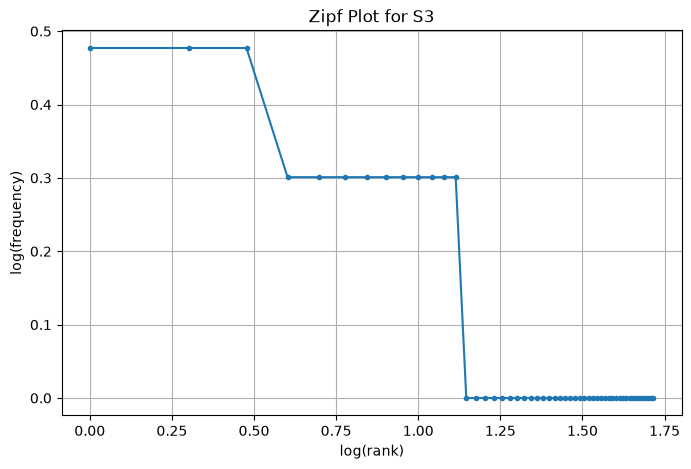


===== TOP 5 BIGRAMS OF S1 =====
('.', 'i'): 4
('.', 'please'): 3
('please', 'help'): 3
('help', '.'): 3
('is', 'running'): 2

===== TOP 5 BIGRAMS OF S3 =====
('please', 'help'): 3
('running', 'slowly'): 2
('uploading', 'file'): 2
('python', 'running'): 1
('slowly', 'problem'): 1


In [9]:

import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams


S1 = []  
S2 = []
S3 = []  

for _, row in df.iterrows():

    result = process_ticket(row["Ticket_Text"])

    S1.extend(result["tokens"])

    S2.extend([
        token for token in result["tokens"]
        if token not in result["punct"]
    ])

    S3.extend(result["final"])


porter = PorterStemmer()

S4 = [porter.stem(token) for token in S3]


def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return total, unique, ttr


stats = []

for name, tokens in [
    ("S1", S1),
    ("S2", S2),
    ("S3", S3),
    ("S4", S4)
]:
    total, unique, ttr = corpus_stats(tokens)

    stats.append({
        "Set": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })


stats_df = pd.DataFrame(stats)

display(stats_df)

print("\n===== TOP 10 WORDS OF S1 =====")

s1_freq = Counter(S1)

for word, freq in s1_freq.most_common(10):
    print(f"{word}: {freq}")

print("\n===== TOP 10 WORDS OF S3 =====")

s3_freq = Counter(S3)

for word, freq in s3_freq.most_common(10):
    print(f"{word}: {freq}")


frequencies = sorted(s3_freq.values(), reverse=True)

ranks = range(1, len(frequencies) + 1)

log_ranks = [math.log10(r) for r in ranks]
log_frequencies = [math.log10(f) for f in frequencies]

plt.figure(figsize=(8, 5))

plt.plot(log_ranks, log_frequencies, marker=".")

plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf Plot for S3")

plt.grid(True)
plt.show()


print("\n===== TOP 5 BIGRAMS OF S1 =====")

s1_bigrams = Counter(bigrams(S1))

for pair, freq in s1_bigrams.most_common(5):
    print(f"{pair}: {freq}")


print("\n===== TOP 5 BIGRAMS OF S3 =====")

s3_bigrams = Counter(bigrams(S3))

for pair, freq in s3_bigrams.most_common(5):
    print(f"{pair}: {freq}")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*